# Time to a Milestone When You Can't Tell the Subjects Apart

Here's a [question from Cross Validated](https://stats.stackexchange.com/questions/677729), the statistics Q&A site:

> I am trying to perform a survival curve/time to event analysis to determine if two treatments cause animal offspring to meet developmental milestones at different ages. [...] I record their behavior daily with a score of 0,1, or 2 (0=not achieved, 1=partial, 2=completely achieved). The problem is that I cannot ID individual offspring every day. [...] Does this cause any problems for Kaplan Meier anaylsis?

To restate the setup: a researcher compares two treatments by the age at which animal offspring reach a developmental milestone. Each litter of pups gets one treatment, and there are several litters per treatment. Every day from P3 to P10, each pup is scored 0 (not achieved), 1 (partial) or 2 (achieved). The pups can't be told apart from day to day, so the rows of the daily table aren't individuals. And now and then a pup that scored 2 one day doesn't show the behavior the next.

Three questions come up:

1. **Do we need individual identities?** For time to a first event, no: the count of pups that have reached the milestone in each litter on each day is enough.
2. **What is the unit of analysis?** The treatment is assigned to litters, so this is a cluster-randomized design. Treating pups as independent overstates the evidence.
3. **What about the pups that "go back"?** They are measurement errors in an outcome that, in reality, only moves forward. We can model the measurement process instead of editing the data.

A Bayesian model handles all three at once. I'll use simulated data, so we can check whether the models recover the true values.

[Click here to run this notebook on Colab](https://colab.research.google.com/github/AllenDowney/DataQnA/blob/main/nb/unlabeled_litters.ipynb).

I'll download a utilities module with some of my frequently-used functions, install PyMC if we're running on Colab, and then import the libraries we'll need.

In [1]:
from os.path import basename, exists

def download(url):
    filename = basename(url)
    if not exists(filename):
        from urllib.request import urlretrieve

        local, _ = urlretrieve(url, filename)
        print("Downloaded " + str(local))
    return filename

download('https://github.com/AllenDowney/DataQnA/raw/main/nb/utils.py');

In [2]:
# on Colab, upgrade the sampling stack together (PyMC 6 uses nutpie when it's installed)

import sys

if "google.colab" in sys.modules:
    %pip install -q "pymc>=6" "arviz>=1.1" nutpie

In [3]:
import numpy as np
np.set_printoptions(legacy='1.25')
import matplotlib.pyplot as plt
import pandas as pd

import pymc as pm
import pytensor.tensor as pt
import arviz as az
from scipy.special import gammaln

from utils import decorate

BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"

## Simulated data

Twelve litters of five pups, six per treatment, observed from P3 to P10. Each pup reaches the milestone on some day; the daily chance of reaching it (the hazard) rises with age, is higher under treatment, and varies from litter to litter. A pup that has reached the milestone shows it on a given day with probability 0.85. Other pups score 0 or 1.

In [4]:
rng = np.random.default_rng(17)

n_pups = 5
days = np.arange(3, 11)  # P3 to P10
n_per_arm = 6
n_litters = 2 * n_per_arm
treatment = np.repeat([0, 1], n_per_arm)

# true values, which the models below try to recover
a_true, c_true, b_true = -2.0, 0.45, 0.8  # baseline, daily increase, treatment (log odds)
sigma_true = 0.5  # litter-to-litter variation
p_true = 0.85  # probability that a pup that has the milestone shows it
u_true = rng.normal(0, sigma_true, n_litters)


def simulate():
    scores = np.zeros((n_litters, len(days), n_pups), dtype=int)
    for i in range(n_litters):
        achieved = np.zeros(n_pups, dtype=bool)
        for t, d in enumerate(days):
            eta = a_true + c_true * (d - 3) + b_true * treatment[i] + u_true[i]
            achieved |= rng.random(n_pups) < 1 / (1 + np.exp(-eta))
            shows = achieved & (rng.random(n_pups) < p_true)
            partial = rng.random(n_pups) < 0.4
            daily = np.where(shows, 2, np.where(partial, 1, 0))
            scores[i, t] = rng.permutation(daily)  # rows are not individuals
    return scores


scores = simulate()

Here is one litter as the researcher sees it: each row is a pup on that day, but row 1 on P5 needn't be row 1 on P6.

In [5]:
pd.DataFrame(scores[0].T, columns=[f"P{d}" for d in days])

,P3,P4,P5,P6,P7,P8,P9,P10
0,0,2,1,2,2,2,2,2
1,0,1,1,2,2,2,2,2
2,2,2,2,1,2,2,2,2
3,0,0,2,2,0,2,1,2
4,1,0,2,2,1,0,2,2


## The counts are all we need

For time to a first event, it doesn't matter which pup reached the milestone, only how many. So we reduce each litter-day to `y`, the number of pups scoring 2.

In [6]:
y = (scores == 2).sum(axis=2)
pd.DataFrame(y, columns=[f"P{d}" for d in days], index=pd.Index(treatment, name="treatment"))

,P3,P4,P5,P6,P7,P8,P9,P10
treatment,,,,,,,,
0,1,2,3,4,3,4,4,5
0,1,3,3,4,5,2,4,4
0,1,1,2,2,3,2,3,3
0,0,0,1,1,3,2,4,5
0,0,0,0,0,1,2,4,3
0,0,1,0,2,2,4,3,4
1,0,3,4,4,5,5,4,4
1,0,1,4,5,4,5,5,4
1,0,2,4,5,4,5,4,5


In a few places the count goes down, because a pup didn't show the behavior that day. If we assume pups don't really lose the milestone, the number that have reached it by day $t$ is at least the largest count seen so far (the cumulative maximum). That gives the number of new events each day and the number still at risk, which is all a discrete-time survival analysis needs.

In [7]:
reached = np.maximum.accumulate(y, axis=1)
before = np.hstack([np.zeros((n_litters, 1), dtype=int), reached[:, :-1]])
new = reached - before
at_risk = n_pups - before

The Kaplan-Meier estimate from these counts is the same as the one from individual records would be (with the cumulative maximum standing in for "first time scored 2"):

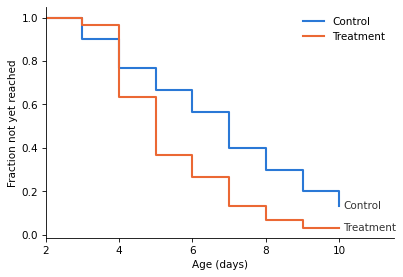

In [8]:
def km(arm):
    rows = treatment == arm
    surv = np.cumprod(1 - new[rows].sum(axis=0) / at_risk[rows].sum(axis=0))
    return surv


fig, ax = plt.subplots(figsize=(6, 4))
for arm, color, label in [(0, BLUE, "Control"), (1, ORANGE, "Treatment")]:
    s = np.concatenate([[1.0], km(arm)])  # nobody has reached it before P3
    ax.step(np.concatenate([[2], days]), s, where="post", color=color, lw=2, label=label)
    ax.text(days[-1] + 0.1, s[-1], label, color="0.2", va="center")
ax.set_xlabel("Age (days)")
ax.set_ylabel("Fraction not yet reached")
ax.set_xlim(2, 11.5)
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False);

The curves can't tell us how sure to be that treatment speeds development, because they treat the 60 pups as independent. The treatment was given to 12 litters.

## Model 1: discrete-time hazard, litter as the unit

On day $t$, each pup in litter $i$ that hasn't reached the milestone reaches it with probability $h_{it}$:

$$\text{logit}(h_{it}) = a + c\,(t - 3) + b\,\text{treatment}_i + u_i, \qquad u_i \sim \text{Normal}(0, \sigma)$$

and the new events are $\text{Binomial}(\text{at risk}_{it}, h_{it})$. The litter effects $u_i$ are what make litters, not pups, the unit of analysis. To see what they do, we fit the model with and without them.

In [9]:
day_offset = days - 3


def hazard(litter_effects=True):
    a = pm.Normal("a", -2, 1.5)
    c = pm.Normal("c", 0, 0.5)
    b = pm.Normal("b", 0, 1)
    if litter_effects:
        sigma = pm.HalfNormal("sigma", 1)
        z = pm.Normal("z", 0, 1, shape=n_litters)
        u = sigma * z
    else:
        u = pt.zeros(n_litters)
    eta = a + c * day_offset[None, :] + b * treatment[:, None] + u[:, None]
    return pm.math.invlogit(eta)


with pm.Model() as pooled:
    h = hazard(litter_effects=False)
    pm.Binomial("new", n=at_risk, p=h, observed=new)
    idata_pooled = pm.sample(random_seed=1, progressbar=False)

with pm.Model() as clustered:
    h = hazard(litter_effects=True)
    pm.Binomial("new", n=at_risk, p=h, observed=new)
    idata_clustered = pm.sample(random_seed=1, target_accept=0.95, progressbar=False)

NUTS[nutpie]: [a, c, b]


NUTS[nutpie]: [a, c, b, sigma, z]


## Model 2: model the misses instead of correcting them

The cumulative maximum fixes the "go back" problem only partly: when a pup reaches the milestone but doesn't show it that day, the event is recorded late, which biases the daily increase $c$ down. Instead we can treat the true number of pups that have reached the milestone, $N_{it}$, as unobserved:

- $N_{it}$ only goes up: $N_{it} = N_{i,t-1} + \text{Binomial}(5 - N_{i,t-1},\ h_{it})$, with the same hazard as before.
- What we see is how many of them show it that day: $y_{it} \sim \text{Binomial}(N_{it},\ p)$.

This is a hidden Markov model with six states (0 to 5 pups). PyMC can't sample discrete latent variables with NUTS, so we sum them out with the forward algorithm, eight steps per litter.

In [10]:
NEG = -1e6  # stands in for log(0); -inf breaks the gradients
states = np.arange(n_pups + 1)
I, J = np.meshgrid(states, states, indexing="ij")  # from state I to state J
k_new = np.clip(J - I, 0, None)
k_rest = np.clip(n_pups - J, 0, None)
can_move = J >= I
log_choose_T = gammaln(n_pups - I + 1) - gammaln(k_new + 1) - gammaln(k_rest + 1)

Y = y[:, :, None]
S = states[None, None, :]
can_show = Y <= S
log_choose_E = np.where(can_show, gammaln(S + 1) - gammaln(Y + 1) - gammaln(np.clip(S - Y, 0, None) + 1), 0.0)

with pm.Model() as hidden:
    h = hazard(litter_effects=True)
    p = pm.Beta("p", 8, 2)
    log_emit = pt.where(can_show, log_choose_E + Y * pt.log(p) + (S - Y) * pt.log1p(-p), NEG)

    # start: no pup has the milestone before P3
    log_alpha = pt.concatenate([pt.zeros((n_litters, 1)), pt.full((n_litters, n_pups), NEG)], axis=1)
    for t in range(len(days)):
        ht = h[:, t][:, None, None]
        log_trans = pt.where(can_move, log_choose_T + k_new * pt.log(ht) + k_rest * pt.log1p(-ht), NEG)
        log_alpha = pt.logsumexp(log_alpha[:, :, None] + log_trans, axis=1) + log_emit[:, t, :]
    pm.Potential("likelihood", pt.logsumexp(log_alpha, axis=1).sum())

    idata_hidden = pm.sample(random_seed=1, target_accept=0.95, progressbar=False)

NUTS[nutpie]: [a, c, b, sigma, z, p]


## Results

In [11]:
fits = {
    "Pups independent (cumulative max)": idata_pooled,
    "Litter effects (cumulative max)": idata_clustered,
    "Litter effects + misses modeled": idata_hidden,
}

rows = []
for name, idata in fits.items():
    post = az.extract(idata)
    b = post["b"].values
    rows.append({
        "model": name,
        "b mean": b.mean(),
        "b 5%": np.quantile(b, 0.05),
        "b 95%": np.quantile(b, 0.95),
        "P(b > 0)": (b > 0).mean(),
        "c mean": post["c"].values.mean(),
    })
results = pd.DataFrame(rows).set_index("model").round(2)
results

,b mean,b 5%,b 95%,P(b > 0),c mean
model,,,,,
Pups independent (cumulative max),0.77,0.26,1.28,0.99,0.26
Litter effects (cumulative max),0.74,0.05,1.41,0.96,0.31
Litter effects + misses modeled,0.79,-0.00,1.55,0.95,0.42


The true values are $b = 0.8$ and $c = 0.45$.

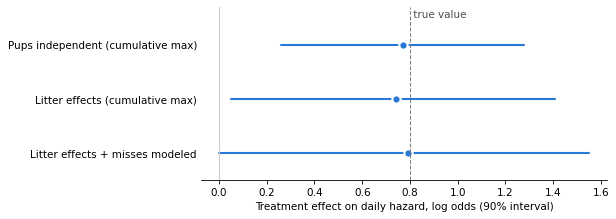

In [12]:
fig, ax = plt.subplots(figsize=(7, 3))
for k, (name, row) in enumerate(results.iloc[::-1].iterrows()):
    ax.plot([row["b 5%"], row["b 95%"]], [k, k], color=BLUE, lw=2, solid_capstyle="round")
    ax.plot(row["b mean"], k, "o", color=BLUE, ms=8, mec="white", mew=2)
ax.axvline(b_true, color="0.5", lw=1, ls="--")
ax.set_ylim(-0.5, len(results) - 0.3)
ax.text(b_true, len(results) - 0.35, " true value", color="0.3", va="top")
ax.axvline(0, color="0.8", lw=1)
ax.set_yticks(range(len(results)), results.index[::-1])
ax.set_xlabel("Treatment effect on daily hazard, log odds (90% interval)")
ax.tick_params(axis="y", length=0)
ax.spines[["top", "right", "left"]].set_visible(False);

What the comparison shows:

- **Ignoring litters overstates certainty.** The model that treats pups as independent gives the narrowest interval, but the narrowness is not real: it counts 60 pups when the treatment was assigned to 12 litters. This is the pseudoreplication problem, and the frequentist `survdiff` on pup rows has it too.
- **The cumulative maximum underestimates how fast pups develop** ($c$ too low), because missed displays delay events.
- **Modeling the misses** recovers both $b$ and $c$, and estimates the detection probability $p$ from the data, with no hand-editing.

What we can report is a posterior probability that treatment speeds development, $P(b > 0)$, and an interval for its size, from a model that matches how the experiment was run.

In [13]:
az.summary(idata_hidden, var_names=["a", "c", "b", "sigma", "p"], round_to=2)

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
a,-2.29,0.44,-3.00,-1.62,1723.28,2012.18,1.0,0.01,0.01
c,0.42,0.13,0.23,0.64,1823.98,2096.93,1.0,0.00,0.00
b,0.79,0.47,0.02,1.53,1983.70,2235.34,1.0,0.01,0.01
sigma,0.61,0.34,0.09,1.18,793.62,802.44,1.0,0.01,0.01
p,0.86,0.03,0.82,0.90,5202.42,3149.60,1.0,0.00,0.00


## Discussion

To answer the question: Kaplan-Meier doesn't need to know which pup is which, but it does need the right data.
Running `survfit` on the rows of the table treats each row as an individual, which it isn't.
The count of pups that have reached the milestone in each litter on each day is enough: it gives the number of new events and the number at risk, which is all a survival analysis uses.

The bigger problem is that the treatment was assigned to litters, not pups.
`survdiff` on pup rows treats every pup as independent, so it overstates the evidence.
A model with litter effects makes litters the unit of analysis, and with only 6 litters per treatment, that makes a real difference in how sure we can be.

The pups that "go back" can be handled by taking the running maximum of the counts, but that makes development look slower than it is.
Modeling the observation process -- pups that have the milestone show it with some probability -- recovers the true values without editing the data.

This structure -- cluster randomization, event times known only to the day, and an imperfect assessment of a state that only moves forward -- is also common in clinical trials, where clinics or wards play the role of litters.

[*Data Q&A: Answering the real questions with Python*](https://allendowney.github.io/DataQnA/index.html)

Copyright 2026 [Allen B. Downey](https://allendowney.com)

License: [Creative Commons Attribution-NonCommercial-ShareAlike 4.0 International](https://creativecommons.org/licenses/by-nc-sa/4.0/)